In [1]:
from ete3 import Tree
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:

import os
from ete3 import Tree
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.io import mmread
# 0. Global figure settings
# =============================================================================

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)


In [ ]:

with open('rerooted_tree_no_germline_node_names.nwk', 'r') as f:

    file_content = f.read()
newick_tree = file_content

# Create a tree object
tree = Tree(newick_tree, format = 1)

# Get the root node
root = tree.get_tree_root()

distances_from_root = {}

# Calculate the distance between the root and each leaf node
for leaf in tree.iter_leaves():
    distances_from_root[str(leaf)[3:41]] = root.get_distance(leaf, topology_only=False) #topology true if we only want to know number of ancestors 

# Signature analysis

In [5]:
import pandas as pd

In [6]:
signatures_data_frame = pd.read_csv("example_vcf_per_cell/Assignment_Solution/Activities/Assignment_Solution_Activities.txt", sep="\t")
signatures_data_frame_no_0 = signatures_data_frame.loc[:, (signatures_data_frame != 0).any(axis=0)]
signatures_data_frame_no_0 = signatures_data_frame_no_0.set_index("Samples")

In [9]:
sig_values_dict = {}
for lf in tree.iter_leaves():
    leaf_name = str(lf)[3:41]
    if leaf_name in signatures_data_frame_no_0.index:
        percentages = signatures_data_frame_no_0.loc[leaf_name].values
        sig_values_dict[leaf_name] = percentages
        


In [10]:
import pandas as pd

# Get all signature names from the original dataset
all_signatures = list(signatures_data_frame_no_0.columns)

# Initialize an empty DataFrame with all signature names as columns
df = pd.DataFrame(columns=all_signatures)

# Iterate over the tree leaves and extract signature values for all columns
for lf in tree.iter_leaves():
    leaf_name = str(lf)[3:41]  # Extract the leaf identifier
    if leaf_name in sig_values_dict:
        # Extract all signature values for this leaf
        df.loc[leaf_name] = sig_values_dict[leaf_name]

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the list of signatures of interest (example, replace with your actual list)
signatures_of_interest = ['SBS1', 'SBS21', 'SBS32', 'SBS12', 'SBS54', 'SBS87', 'SBS37', 'SBS40c', 'SBS5']  # Replace with your actual signature names

# Filter the DataFrame to include only the signatures of interest
df_interest = df[signatures_of_interest]

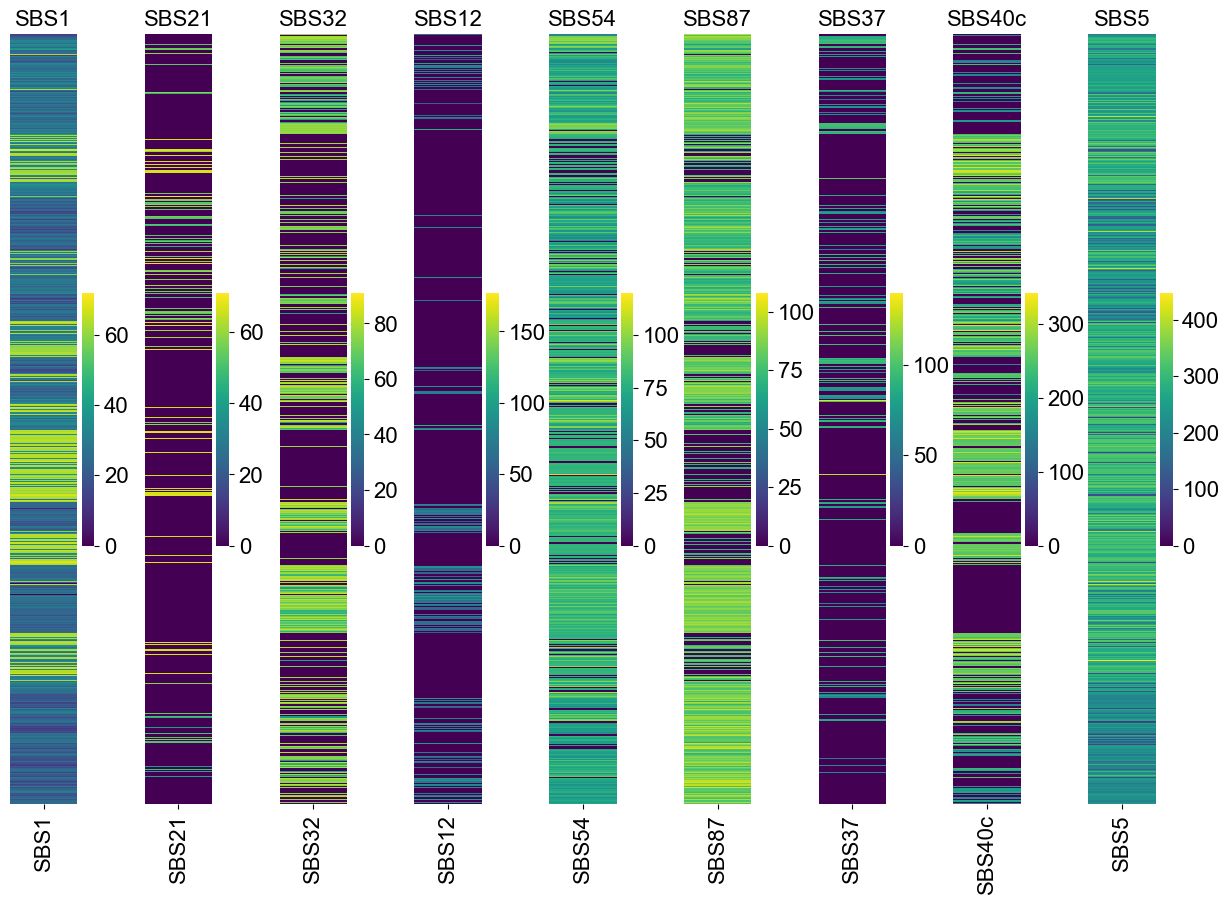

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

signatures = df_interest.columns
num_signatures = len(signatures)

fig, axes = plt.subplots(
    1,
    num_signatures,
    figsize=(15, 10),
    sharey=True
)

if num_signatures == 1:
    axes = [axes]

for ax, sig in zip(axes, signatures):
    hm = sns.heatmap(
        df_interest[[sig]],
        yticklabels=False,
        xticklabels=True,
        cmap="viridis",
        cbar=True,
        ax=ax,
    )

    cbar = hm.collections[0].colorbar
    cbar.ax.tick_params(labelsize=16)
    
    ax.set_title(sig, fontsize=16)
    ax.tick_params(axis="x", labelrotation=90, labelsize=16)

plt.subplots_adjust(wspace=0.6)

plt.savefig(
    "sigs.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
